# Topic 5: Baryon acoustic oscillations: Part 2
**Group members: Evan Balwani, Niko Jamison, Logan Lajiness**  
**Group size: 3 people**  
**Extension(s) chosen: both**  

**Work plan (who owns which module; see Common Instructions section 4):**  
- Module A, Physics: Niko Jamison
- Module B, Code: Evan Balwani, Logan Lajiness
- Module C, Validation and figures: Evan Balwani, Logan Lajiness
- Reviewers:  


## Summary
*(At most 150 words: what you derived, what you computed, the main takeaway.)*

In [1]:
# Setup: imports, constants, seed, data path
import numpy as np
import scipy
import matplotlib.pyplot as plt
# import pandas as pd

rng = np.random.default_rng(5682)   # fixed seed, for reproducibility
DATA = './data/'                    # read files from here; do not use absolute paths

# Physical constants (state units!):
c = 299792.458 # km/s
hubble_const = 67.36 # km/s/Mpc
omega_m = 0.3138 # unitless
omega_lambda = 1 - omega_m # unitless
r_d = 147.09 # Mpc

h = 0.6736 # unitless
r_d_h = 99.1 # Mpc/h

# Constants for Code 2 
A = .01               # unitless
gamma = 1.8           # unitless
B = .002              # unitless
r_bao = 100           # Mpc/h
sigma = 10.0          # Mpc/h

r_taper = 300         # Mpc/h
r_min = .01           # Mpc/h
r_max = 1000          # Mpc/h


## Physics and derivations
*Step by step, with LaTeX. Mark the final result, state assumptions, define every symbol and unit.*

### Physics 1: Origin of the ruler

When photons and baryons were coupled in the early universe, radiation pressure from photons caused over and under densities, or sound waves, of baryonic matter. When photons and baryons decoupled at the drag epoch ($z_d \approx 1060$), the radiation pressure ceased, and these sound waves were frozen leaving a spherical shell around the original overdensity. After the drag epoch, the universe continued to expand, expanding the physical seperation of the sound waves, but the comoving seperation ($r_d$) remained approximately constant. 

### Physics 2: Observable sizes

The BAO scale $r_d$ is a comoving distance. For a transverse measurement, the angular separation is related to the comoving transverse distance $D_M(z)$ using the small-angle approximation.

$$\tan\left(\frac{\Delta\theta}{2}\right)=\frac{r_d}{2D_M(z)}$$

For small angles, $\tan(\Delta\theta/2)\approx\Delta\theta/2$, giving

$$\Delta\theta=\frac{r_d}{D_M(z)}$$

We can also express this using the angular diameter distance $d_A(z)$. The proper size of the BAO scale at redshift $z$ is $a(z)r_d$, where $a(z)=1/(1+z)$.

$$\Delta\theta=\frac{a(z)r_d}{d_A(z)}$$

Substituting the scale factor gives

$$\Delta\theta=\frac{r_d}{(1+z)d_A(z)}$$

Therefore,

$$\boxed{\Delta\theta=\frac{r_d}{D_M(z)}=\frac{r_d}{(1+z)d_A(z)}}$$

For the radial direction, the comoving distance is

$$D_C(z)=c\int_0^z\frac{dz'}{H(z')}$$

For a small redshift interval $\Delta z$,

$$\Delta D_C\approx\frac{c}{H(z)}\Delta z$$

Since the BAO scale is $r_d$, we set $\Delta D_C=r_d$:

$$r_d\approx\frac{c}{H(z)}\Delta z$$

Rearranging gives

$$\boxed{\Delta z\approx\frac{H(z)r_d}{c}}$$

Finally, defining $D_H(z)=c/H(z)$, the dimensionless distance combinations are

$$\boxed{\frac{D_M(z)}{r_d}\quad\text{and}\quad\frac{D_H(z)}{r_d}}$$


### Physics 3: Isotropic distance $D_V$

As you average the correlation function over all three directions, you have two transverse directions and one radial direction. The transverse directions both have a factor of $\alpha_\perp$, and the radial direction has a factor of $\alpha_\parallel$. Combining these three directions gives a volume dilation of $\alpha_\perp^2\alpha_\parallel$. Due to the 3D volume, you take the cube root to get a distance scale.

$$
\alpha_{\mathrm{eff}} = (\alpha_\perp^2\alpha_\parallel)^{1/3}
$$

The two transverse directions depend on $D_M(z)$, and the radial direction depends on the Hubble distance $c/H(z)$. Combining these gives an effective volume proportional to $D_M^2(z)c/H(z)$. Taking the cube root gives the isotropic distance scale:

$$
\boxed{D_V(z) = \left[zD_M^2(z)\frac{c}{H(z)}\right]^{1/3}}
$$


### Physics 4: From xi(r) to P(k)



We start with the three-dimensional Fourier transform: 

 

$$ 

P(\mathbf{k})=\int \xi(\mathbf{r})e^{-i\mathbf{k}\cdot\mathbf{r}}\,d^3r 

$$ 

 

The wavenumber is defined as 

 

$$ 

k=\frac{2\pi}{\lambda} 

$$ 

 

Converting to spherical coordinates, the volume element is 

 

$$ 

d^3r=r^2\sin\theta\,dr\,d\theta\,d\phi 

$$ 

 

Using the polar axis along $\mathbf{k}$ gives 

 

$$ 

\mathbf{k}\cdot\mathbf{r}=kr\cos\theta 

$$ 

 

Therefore, 

 

$$ 

P(k)=\int_0^\infty\int_0^\pi\int_0^{2\pi} 

\xi(r)e^{-ikr\cos\theta}r^2\sin\theta 

\,d\phi\,d\theta\,dr 

$$ 

 

Integrating over $\phi$: 

 

$$ 

\int_0^{2\pi}d\phi=2\pi 

$$ 

 

This gives 

 

$$ 

P(k)=2\pi\int_0^\infty\xi(r)r^2 

\left[\int_0^\pi e^{-ikr\cos\theta}\sin\theta\,d\theta\right]dr 

$$ 

 

Using the substitution 

 

$$ 

u=\cos\theta,\qquad du=-\sin\theta\,d\theta 

$$ 

 

the angular integral becomes 

 

$$ 

\int_{-1}^{1}e^{-ikru}\,du 

$$ 

 

Integrating gives 

 

$$ 

=\frac{e^{-ikr}-e^{ikr}}{-ikr} 

$$ 

 

Using Euler's identity, 

 

$$ 

e^{ix}-e^{-ix}=2i\sin x 

$$ 

 

we obtain 

 

$$ 

\int_{-1}^{1}e^{-ikru}\,du 

=\frac{2\sin(kr)}{kr} 

$$ 

 

Substituting back: 

 

$$ 

P(k)=2\pi\int_0^\infty 

\xi(r)r^2\frac{2\sin(kr)}{kr}\,dr 

$$ 

 

Therefore, 

 

$$ 

\boxed{P(k)=4\pi\int_0^\infty 

\xi(r)\frac{\sin(kr)}{kr}r^2\,dr} 

$$ 

 

### Inverse Fourier Transform 

 

The inverse transform is 

 

$$ 

\boxed{\xi(r)=\frac{1}{2\pi^2} 

\int_0^\infty P(k)\frac{\sin(kr)}{kr}k^2\,dk} 

$$ 

 

### Why a 1D Fourier Transform Is Incorrect 

 

A one-dimensional Fourier transform is incorrect because the galaxy correlation function describes separations in three-dimensional space. Although the correlation function only depends on the distance $r$, it is still three-dimensional, so we must integrate over all spatial directions. This introduces the spherical volume factor $r^2$ and the angular factor $\sin(kr)/(kr)$, which would be missing in a one-dimensional Fourier transform. 

### Physics 5: Wiggles from a bump



We start with a narrow Gaussian bump in the correlation function: 

 

$$ 

\xi_{\mathrm{bump}}(r)=B\exp\left[-\frac{(r-r_{\mathrm{BAO}})^2}{2\sigma^2}\right] 

$$ 

 

where $B$ is the amplitude, $r_{\mathrm{BAO}}$ is the location of the bump, and $\sigma$ is its width. We assume $\sigma \ll r_{\mathrm{BAO}}$. 

 

### Step 1: Substitute into the Fourier transform 

 

From Physics 4, the three-dimensional Fourier transform is 

 

$$ 

P(k)=4\pi\int_0^\infty \xi(r)\frac{\sin(kr)}{kr}r^2\,dr 

$$ 

 

Substituting the Gaussian bump gives 

 

$$ 

P_{\mathrm{bump}}(k)=4\pi B\int_0^\infty 

e^{-\frac{(r-r_{\mathrm{BAO}})^2}{2\sigma^2}} 

\frac{r\sin(kr)}{k}\,dr 

$$ 

 

### Step 2: Apply the narrow-bump approximation 

 

Since the Gaussian is concentrated near $r=r_{\mathrm{BAO}}$, we approximate the slowly varying factor as 

 

$$ 

\frac{r}{k}\approx\frac{r_{\mathrm{BAO}}}{k} 

$$ 

 

Therefore, 

 

$$ 

P_{\mathrm{bump}}(k)\approx 

\frac{4\pi B r_{\mathrm{BAO}}}{k} 

\int_0^\infty 

e^{-\frac{(r-r_{\mathrm{BAO}})^2}{2\sigma^2}} 

\sin(kr)\,dr 

$$ 

 

Let 

 

$$ 

u=r-r_{\mathrm{BAO}} 

$$ 

 

Because the Gaussian is narrow and centered far from zero, we extend the integration limits to $(-\infty,\infty)$: 

 

$$ 

P_{\mathrm{bump}}(k)\approx 

\frac{4\pi B r_{\mathrm{BAO}}}{k} 

\int_{-\infty}^{\infty} 

e^{-u^2/(2\sigma^2)} 

\sin[k(u+r_{\mathrm{BAO}})]\,du 

$$ 

 

### Step 3: Evaluate the Gaussian integral 

 

Using the trigonometric identity 

 

$$ 

\sin[k(u+r_{\mathrm{BAO}})] 

= 

\sin(ku)\cos(kr_{\mathrm{BAO}}) 

+ 

\cos(ku)\sin(kr_{\mathrm{BAO}}) 

$$ 

 

The term containing $\sin(ku)$ integrates to zero because it is an odd function multiplied by an even Gaussian. 

 

The remaining integral is 

 

$$ 

\int_{-\infty}^{\infty} 

e^{-u^2/(2\sigma^2)}\cos(ku)\,du 

= 

\sqrt{2\pi}\sigma e^{-k^2\sigma^2/2} 

$$ 

 

Substituting back gives 

 

$$ 

\boxed{ 

P_{\mathrm{bump}}(k)\approx 

4\pi B r_{\mathrm{BAO}}\sqrt{2\pi}\sigma 

\frac{\sin(kr_{\mathrm{BAO}})}{k} 

e^{-k^2\sigma^2/2} 

} 

$$ 

 

### Step 4: Find the oscillation period 

 

The oscillations come from the sine factor 

 

$$ 

\sin(kr_{\mathrm{BAO}}) 

$$ 

 

Since the sine function repeats every $2\pi$, 

 

$$ 

\Delta k\,r_{\mathrm{BAO}}=2\pi 

$$ 

 

Rearranging gives 

 

$$ 

\boxed{\Delta k=\frac{2\pi}{r_{\mathrm{BAO}}}} 

$$ 

 

For $r_{\mathrm{BAO}}=100\,h^{-1}\mathrm{Mpc}$, 

 

$$ 

\Delta k=\frac{2\pi}{100\,h^{-1}\mathrm{Mpc}} 

$$ 

 

Therefore, 

 

$$ 

\boxed{\Delta k\approx0.0628\,h\,\mathrm{Mpc}^{-1}} 

$$ 

 

### Step 5: Explain the damping 

 

The exponential factor 

 

$$ 

e^{-k^2\sigma^2/2} 

$$ 

 

reduces the amplitude of the oscillations as $k$ increases. 

 

When 

 

$$ 

k\gtrsim\frac{1}{\sigma} 

$$ 

 

the oscillations become increasingly damped. A wider Gaussian bump in real space produces stronger damping at smaller values of $k$. 

 

### Conclusion 

 

A localized Gaussian bump in the galaxy correlation function $\xi(r)$ produces oscillations in the power spectrum $P(k)$. The location of the bump, $r_{\mathrm{BAO}}$, determines the oscillation period $\Delta k=2\pi/r_{\mathrm{BAO}}$, while the width $\sigma$ determines how quickly the oscillations are damped. Nonlinear evolution broadens the real BAO feature, causing additional damping of the oscillations in the power spectrum. 

## Code
*Functions with docstrings giving inputs, outputs, and units.*

### Code 1: H(z), D_M, D_H, D_V; Delta theta and Delta z

In [2]:
# function of Hubble parameter
def H_z(z, hubble_const, omega_m):
    '''
    Calculates the Hubble parameter at a given redshift for a flat model
    Enter your value of z, returns in units of km/s/Mpc
    '''
    # setting omega_lambda for a flat universe
    omega_lambda = 1 - omega_m

    # calculating Hubble parameter
    H = hubble_const * np.sqrt(omega_m * (1 + z)**3 + omega_lambda)

    return H

# function of comoving distance
def D_M(z, hubble_const, omega_m):
    '''
    Calculates the transverse comoving distance at a given redshift for a flat model
    Enter your value of z, returns in units of Mpc
    '''
    # setting omega_lambda for a flat universe
    omega_lambda = 1 - omega_m

    # setting up the integral
    def integral(z):
        return 1 / np.sqrt(omega_m * (1 + z)**3 + omega_lambda)

    # integrating from 0 to z
    integral = scipy.integrate.quad(integral, 0, z)[0]

    # calculating comoving distance in Mpc
    distance = (c / hubble_const) * integral

    return distance

# function of Hubble distance
def D_H(z, hubble_const, omega_m):
    '''
    Calculates the Hubble distance at a given redshift for a flat model
    Enter your value of z, returns in units of Mpc
    '''
    # setting omega_lambda for a flat universe
    omega_lambda = 1 - omega_m

    # calling previous Hubble parameter
    H = H_z(z, hubble_const, omega_m)

    # calculating Hubble distance in Mpc
    distance = c / H

    return distance

# function of volume-averaged distance
def D_V(z, hubble_const, omega_m):
    '''
    Calculates the volume-averaged distance at a given redshift for a flat model
    Enter your value of z, returns in units of Mpc
    '''
    # setting omega_lambda for a flat universe
    omega_lambda = 1 - omega_m

    # calling transverse comoving distance
    transverse = D_M(z, hubble_const, omega_m)

    # calling Hubble distance
    hubble = D_H(z, hubble_const, omega_m)

    # calculating volume-averaged distance in Mpc
    distance = (z * hubble * transverse**2) ** (1/3)

    return distance

# function Angular BAO scale in degrees
def delta_theta(z, hubble_const, omega_m, r_d):
    '''
    Calculates the angular BAO scale in degrees
    Enter your value of z, returns in units of degrees
    '''
     # setting omega_lambda for a flat universe
    omega_lambda = 1 - omega_m
    
    # calling transverse comoving distance
    transverse = D_M(z, hubble_const, omega_m)
    
    # converting angular distance to radians
    theta = r_d / transverse

    # converting radians to degrees
    theta = theta * (180 / np.pi)

    return theta

# function for Radial BAO scale
def delta_z(z, hubble_const, omega_m, r_d):
    '''
    Calculates the radial BAO scale
    Enter your value of z, returns in units of redshift
    '''
     # setting omega_lambda for a flat universe
    omega_lambda = 1 - omega_m

    # calling Hubble distance
    hubble = D_H(z, hubble_const, omega_m)

    # calculating radial redshift separation
    separation = r_d / hubble

    return separation

### Code 2: xi_model and P_of_k

In [8]:
# Correlation Function
def xi_model(r, A, gamma, B, r_bao, sigma):
    smooth = A * (r / 100.0)**(-gamma)
    bump = B * np.exp(-((r - r_bao) ** 2) / (sigma**2))
    return smooth + bump

def P_ofk(xi_func, k, A, gamma, B, r_bao, sigma,
          r_taper, r_min, r_max):
    def _calc_single_k(k_val):
        def integrand(r):
            taper = np.exp(-r / r_taper)
            xi_val = xi_func(r, A, gamma, B, r_bao, sigma)
            
            if k_val == 0:
                return 4.0 * np.pi * (r**2) * xi_val * taper
            return (4.0 * np.pi / k_val) * r * xi_val * np.sin(k_val * r) * taper

        val, _ = scipy.integrate.quad(integrand, r_min, r_max, limit=200)
        return val

    if np.isscalar(k):
        return _calc_single_k(k)
    return np.array([_calc_single_k(kv) for kv in k])

# Smooth background for P_k
def xi_smooth_func(r, A, gamma, B, r_bao, sigma):
    return A * (r / 100.0)**(-gamma)

## Results
*Every plot: labeled axes with units, a legend, and a one- or two-sentence caption.*

### Plot 1: D_M/r_d, D_H/r_d, D_V/r_d vs. z for three Omega_m

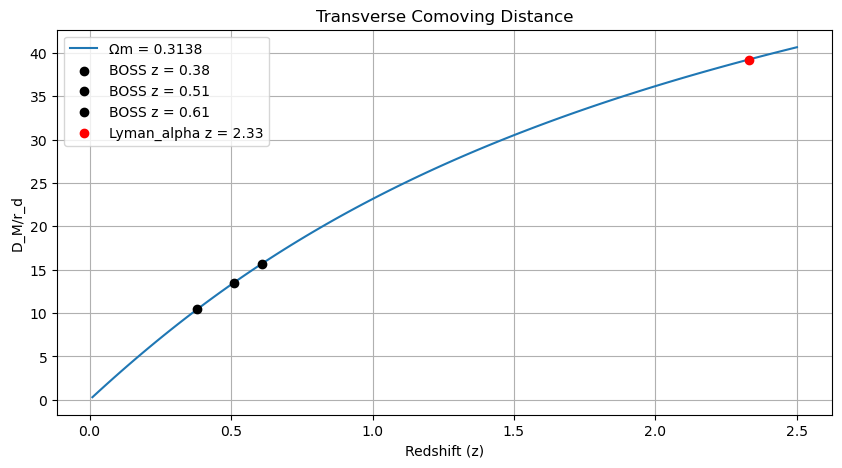

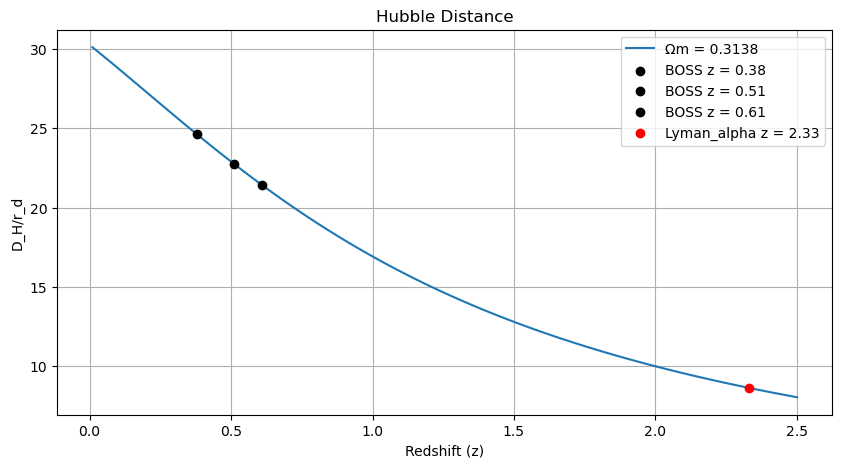

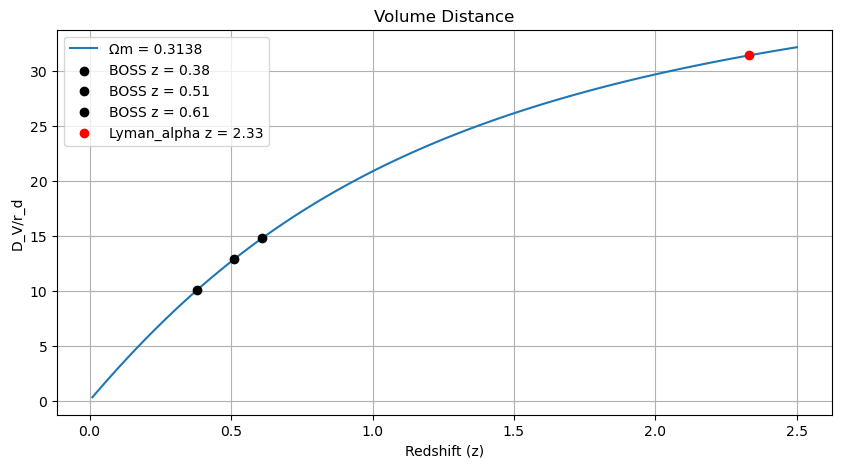

In [9]:
# setting redshift range
z_range = np.linspace(0.01, 2.5, 100)

# setting three matter density values
omega_values = [0.25, 0.30, 0.35]

# setting redshifts markers for BOSS and Lyman-alpha BAO
boss_redshifts = [0.38, 0.51, 0.61]
lyman_alpha_redshift = [2.33]

# plotting D_M vs z for Omega m = 0.25, 0.30, 0.35
plt.figure(figsize=(10, 5))
# calculating D_M/r_d for each redshift value
DM_values = [D_M(z, hubble_const, omega_m) / r_d for z in z_range]
plt.plot(z_range, DM_values, label=f'Ωm = {omega_m}')
# adding boss markers
for redshift in boss_redshifts:
    distance = D_M(redshift, hubble_const, omega_m) / r_d
    plt.scatter(redshift, distance, color='black', marker='o', zorder=5, label=f'BOSS z = {redshift}')
# adding lyman_alpha markers
for redshift in lyman_alpha_redshift:
    distance = D_M(redshift, hubble_const, omega_m) / r_d
    plt.scatter(redshift, distance, color='red', marker='o', zorder=5, label=f'Lyman_alpha z = {redshift}')
# adding labels and title
plt.xlabel('Redshift (z)')
plt.ylabel('D_M/r_d')
plt.title('Transverse Comoving Distance')
plt.grid(True)
plt.legend()

# plotting D_H vs z for Omega m = 0.25, 0.30, 0.35
plt.figure(figsize=(10, 5))
# calculating D_H/r_d for each redshift value
DH_values = [D_H(z, hubble_const, omega_m) / r_d for z in z_range]
plt.plot(z_range, DH_values, label=f'Ωm = {omega_m}')
# adding boss markers
for redshift in boss_redshifts:
    distance = D_H(redshift, hubble_const, omega_m) / r_d
    plt.scatter(redshift, distance, color='black', marker='o', zorder=5, label=f'BOSS z = {redshift}')
# adding lyman_alpha markers
for redshift in lyman_alpha_redshift:
    distance = D_H(redshift, hubble_const, omega_m) / r_d
    plt.scatter(redshift, distance, color='red', marker='o', zorder=5, label=f'Lyman_alpha z = {redshift}')
# adding labels and title
plt.xlabel('Redshift (z)')
plt.ylabel('D_H/r_d')
plt.title('Hubble Distance')
plt.grid(True)
plt.legend()

# plotting D_V vs z for Omega m = 0.25, 0.30, 0.35
plt.figure(figsize=(10, 5))
# calculating D_V/r_d for each redshift value
DV_values = [D_V(z, hubble_const, omega_m) / r_d for z in z_range]
plt.plot(z_range, DV_values, label=f'Ωm = {omega_m}')
# adding boss markers
for redshift in boss_redshifts:
    distance = D_V(redshift, hubble_const, omega_m) / r_d
    plt.scatter(redshift, distance, color='black', marker='o', zorder=5, label=f'BOSS z = {redshift}')
# adding lyman_alpha markers
for redshift in lyman_alpha_redshift:
    distance = D_V(redshift, hubble_const, omega_m) / r_d
    plt.scatter(redshift, distance, color='red', marker='o', zorder=5, label=f'Lyman_alpha z = {redshift}')
# adding labels and title
plt.xlabel('Redshift (z)')
plt.ylabel('D_V/r_d')
plt.title('Volume Distance')
plt.grid(True)
plt.legend()

**Caption:** 

The first plot shows the transverse comoving distance divided by the sound horizon against redshift for three different values of the matter density parameter, Omega_m. The black markers show the reference cosmology at the BOSS redshifts z=0.38, 0.51, 0.61 and the Lyman-alpha redshift z=2.33.

The second plot shows the hubble distance divided by the sound horizon against redshift for three different values of the matter density parameter, Omega_m. The black markers show the reference cosmology at the BOSS and Lyman-alpha BAO redshifts, allowing the distances to be compared across different redshifts.

The third plot shows the volume-averaged distance divided by the sound horizon against redshift for three different values of the matter density parameter, Omega_m. The black markers show the reference cosmology at the BOSS and Lyman-alpha BAO redshifts, illustrating how the volume-averaged distance changes with redshift.


### Plot 2: Delta theta(z) and Delta z(z)

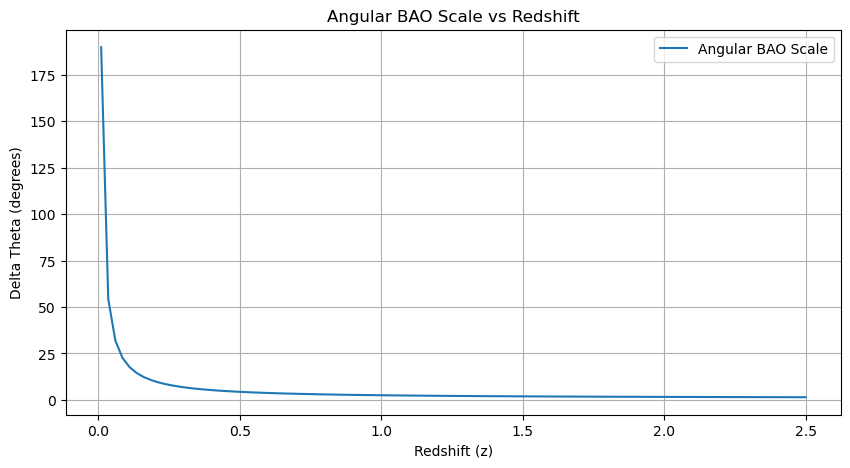

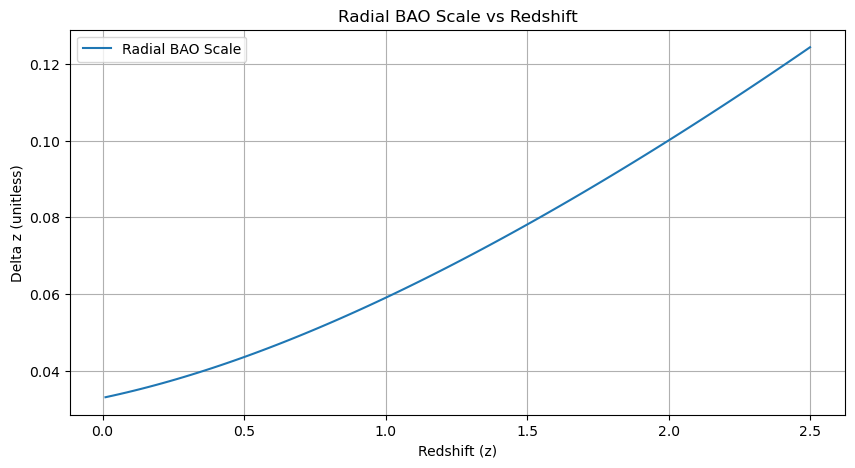

In [10]:
# restating the redshift range
z_values = np.linspace(0.01, 2.5, 100)

# plotting angular BAO scale
plt.figure(figsize=(10, 5))
# calculating angular BAO scale
theta_values = [delta_theta(z, hubble_const, omega_m, r_d) for z in z_values]
plt.plot(z_values, theta_values, label='Angular BAO Scale')
# adding labels and title
plt.xlabel('Redshift (z)')
plt.ylabel('Delta Theta (degrees)')
plt.title('Angular BAO Scale vs Redshift')
plt.grid(True)
plt.legend()
plt.show()


# plotting radial BAO scale
plt.figure(figsize=(10, 5))
# calculating radial BAO scale
delta_z_values = [delta_z(z, hubble_const, omega_m, r_d) for z in z_values]
plt.plot(z_values, delta_z_values, label='Radial BAO Scale')
# labeling plot
plt.xlabel('Redshift (z)')
plt.ylabel('Delta z (unitless)')
plt.title('Radial BAO Scale vs Redshift')
plt.grid(True)
plt.legend()
plt.show()

**Caption:** 

The first plot shows the angular BAO scale, Delta theta, against redshift using the reference cosmological parameters. The plot shows how the apparent angular separation of the BAO feature changes as the distance to the observed objects increases.

The second plot shows the radial BAO scale, Delta z, against redshift using the reference cosmological parameters. It shows the redshift separation corresponding to the sound horizon and how this separation changes with redshift.

### Plot 3: Toy r^2 xi(r)

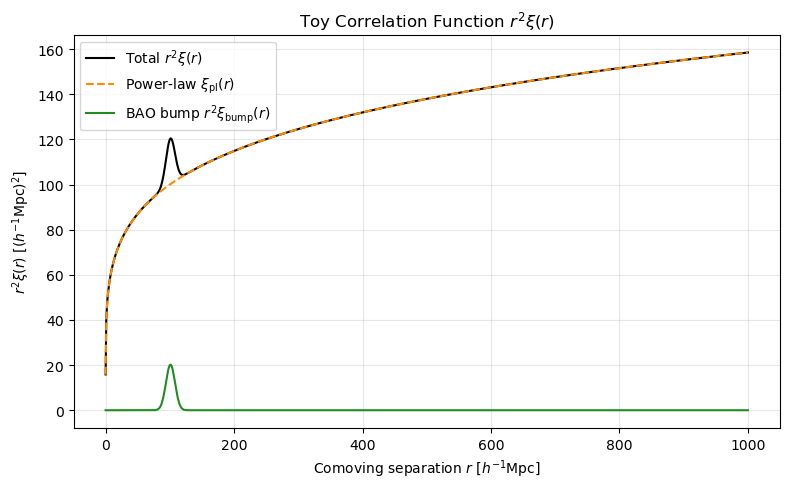

In [11]:
# Grid of r values up to r_max
r_vals = np.linspace(r_min, r_max, 1000)

# Evaluate model components using xi_model
xi_total = xi_model(r_vals, A, gamma, B, r_bao, sigma)
xi_smooth = xi_model(r_vals, A, gamma, 0, r_bao, sigma)
xi_bump = B * np.exp(-((r_vals - r_bao) ** 2) / (sigma**2))

# Plot r^2 * xi(r)
plt.figure(figsize=(8, 5))
plt.plot(r_vals, (r_vals**2) * xi_total, label=r'Total $r^2\xi(r)$', color='black')
plt.plot(r_vals, (r_vals**2) * xi_smooth, label=r'Power-law $\xi_{\mathrm{pl}}(r)$', color='darkorange', linestyle='--')
plt.plot(r_vals, (r_vals**2) * xi_bump, label=r'BAO bump $r^2\xi_{\mathrm{bump}}(r)$', color='forestgreen')

plt.xlabel(r'Comoving separation $r$ [$h^{-1}\mathrm{Mpc}$]')
plt.ylabel(r'$r^2 \xi(r)$ [$(h^{-1}\mathrm{Mpc})^2$]')
plt.title(r'Toy Correlation Function $r^2 \xi(r)$')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

**Caption:** 

### Plot 4: P(k) with and without the bump, vs. the analytic approximation

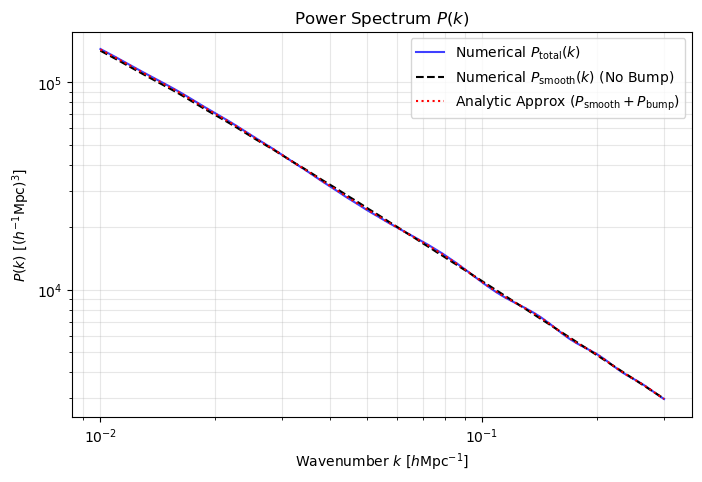

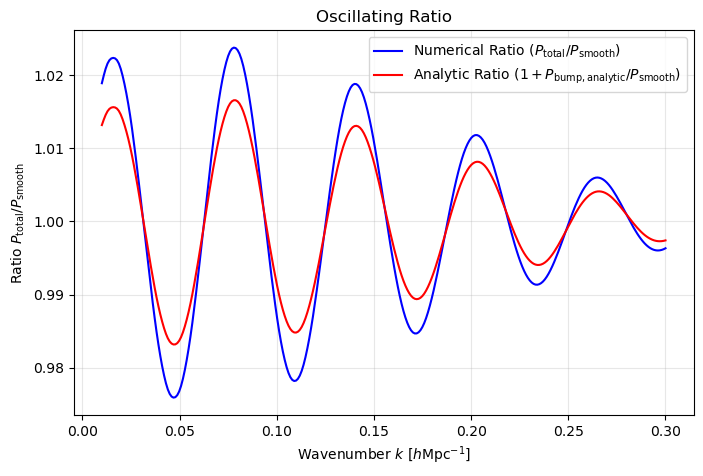

In [17]:
# Wavenumber range
k_vals = np.linspace(0.01,0.3, 300)


# Numerical power spectra integrations (passing A = 0.01)
P_total_num = P_ofk(xi_model, k_vals, A, gamma, B,
                    r_bao, sigma, r_taper, r_min, r_max)
P_smooth_num = P_ofk(xi_smooth_func, k_vals, A, gamma, B,
                     r_bao, sigma, r_taper, r_min, r_max)

# Analytic approximation of BAO bump
P_bump_analytic = (2.0 * np.pi**1.5 * B * sigma * r_bao / k_vals) * np.exp(-(k_vals**2 * sigma**2) / 4.0) * np.sin(k_vals * r_bao)
P_total_analytic = P_smooth_num + P_bump_analytic

# Oscillating ratio
ratio_num = P_total_num / P_smooth_num
ratio_analytic = P_total_analytic / P_smooth_num

# Log-Log Power Spectrum Comparison
plt.figure(figsize=(8, 5))
plt.loglog(k_vals, P_total_num, label=r'Numerical $P_{\mathrm{total}}(k)$', color='blue', alpha=.75)
plt.loglog(k_vals, P_smooth_num, label=r'Numerical $P_{\mathrm{smooth}}(k)$ (No Bump)', color='black', linestyle='--')
plt.loglog(k_vals, P_total_analytic, label=r'Analytic Approx ($P_{\mathrm{smooth}} + P_{\mathrm{bump}}$)',
           color='red', linestyle=':')
plt.xlabel(r'Wavenumber $k$ [$h\mathrm{Mpc}^{-1}$]')
plt.ylabel(r'$P(k)$ [$(h^{-1}\mathrm{Mpc})^3$]')
plt.title(r'Power Spectrum $P(k)$')
plt.grid(True, which='both', alpha=0.3)
plt.legend()
plt.show()

# Oscillating Ratio
plt.figure(figsize=(8, 5))
plt.plot(k_vals, ratio_num, label=r'Numerical Ratio ($P_{\mathrm{total}} / P_{\mathrm{smooth}}$)', color='blue')
plt.plot(k_vals, ratio_analytic, label=r'Analytic Ratio ($1 + P_{\mathrm{bump, analytic}} / P_{\mathrm{smooth}}$)', color='red')
plt.xlabel(r'Wavenumber $k$ [$h\mathrm{Mpc}^{-1}$]')
plt.ylabel(r'Ratio $P_{\mathrm{total}} / P_{\mathrm{smooth}}$')
plt.title('Oscillating Ratio')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

**Caption:** 

## Validation
*Run each check listed on your topic page; report what you found, including failures and what you did about them. The `check` helper below prints PASS or FAIL; use it or `np.isclose`/`assert`.*

In [10]:
def check(name, value, expected, rtol=1e-2, atol=0.0):
    """Print PASS/FAIL comparing value with expected (relative tolerance rtol)."""
    ok = np.isclose(value, expected, rtol=rtol, atol=atol)
    print(f"{'PASS' if ok else 'FAIL'}  {name}: got {value:.6g}, expected {expected:.6g}")
    return ok

# Example of use (replace with your own checks):
# check("name of check", your_function(args), value_from_topic_page, rtol=3e-3)

### Check 1: Table of D_M/r_d, D_H/r_d, D_V/r_d, Delta theta, Delta z at the listed redshifts

In [11]:
# updating check function with new tolerance
def check(name, value, expected, rtol=3e-3, atol=0.0):
    """Print PASS/FAIL comparing value with expected (relative tolerance rtol)."""
    ok = np.isclose(value, expected, rtol=rtol, atol=atol)
    print(f"{'PASS' if ok else 'FAIL'}  {name}: got {value:.6g}, expected {expected:.6g}")
    return ok

# setting redshifts
validation_redshifts = [0.38, 0.51, 0.61, 1.00, 2.33]

# expected values for each redshift
validation_DM = [10.43, 13.51, 15.72, 23.15, 39.24]
validation_DH = [24.62, 22.77, 21.42, 16.92, 8.64]
validation_DV = [10.06, 12.84, 14.78, 20.86, 31.41]
validation_theta = [5.49, 4.24, 3.65, 2.48, 1.46]
validation_delta_z = [0.0406, 0.0439, 0.0467, 0.0591, 0.1158]

# calculating and checking each value
for i, z in enumerate(validation_redshifts):

    # calculating distance ratios
    DM_ratio = D_M(z, hubble_const, omega_m) / r_d
    DH_ratio = D_H(z, hubble_const, omega_m) / r_d
    DV_ratio = D_V(z, hubble_const, omega_m) / r_d

    # calculating BAO scales
    theta = delta_theta(z, hubble_const, omega_m, r_d)
    redshift_separation = delta_z(z, hubble_const, omega_m, r_d)

    # checking calculated values against expected values
    print(f"\nRedshift z = {z}")

    check("D_M/r_d", DM_ratio, validation_DM[i])
    check("D_H/r_d", DH_ratio, validation_DH[i])
    check("D_V/r_d", DV_ratio, validation_DV[i])
    check("Delta theta", theta, validation_theta[i])
    check("Delta z", redshift_separation, validation_delta_z[i])


Redshift z = 0.38
PASS  D_M/r_d: got 10.4296, expected 10.43
PASS  D_H/r_d: got 24.6161, expected 24.62
PASS  D_V/r_d: got 10.058, expected 10.06
PASS  Delta theta: got 5.49357, expected 5.49
PASS  Delta z: got 0.0406238, expected 0.0406

Redshift z = 0.51
PASS  D_M/r_d: got 13.5083, expected 13.51
PASS  D_H/r_d: got 22.7649, expected 22.77
PASS  D_V/r_d: got 12.8434, expected 12.84
PASS  Delta theta: got 4.24153, expected 4.24
PASS  Delta z: got 0.0439272, expected 0.0439

Redshift z = 0.61
PASS  D_M/r_d: got 15.7168, expected 15.72
PASS  D_H/r_d: got 21.418, expected 21.42
PASS  D_V/r_d: got 14.7779, expected 14.78
PASS  Delta theta: got 3.64551, expected 3.65
PASS  Delta z: got 0.0466896, expected 0.0467

Redshift z = 1.0
PASS  D_M/r_d: got 23.1535, expected 23.15
PASS  D_H/r_d: got 16.9235, expected 16.92
PASS  D_V/r_d: got 20.8565, expected 20.86
PASS  Delta theta: got 2.47461, expected 2.48
PASS  Delta z: got 0.0590893, expected 0.0591

Redshift z = 2.33
PASS  D_M/r_d: got 39.23

### Check 2: D_V/r_d at z = 0.51 for three Omega_m

In [12]:
# setting matter density values
omega_values = [0.25, 0.30, 0.35]

# setting expected volume-averaged distance ratios
validation_DV = [13.24, 12.93, 12.63]

# checking volume-averaged distance for each matter density
for i, omega in enumerate(omega_values):

    # calculating volume-averaged distance ratio
    DV_ratio = D_V(0.51, hubble_const, omega) / r_d

    # checking calculated value
    check(f"D_V/r_d for omega_m = {omega}", DV_ratio, validation_DV[i])

PASS  D_V/r_d for omega_m = 0.25: got 13.2437, expected 13.24
PASS  D_V/r_d for omega_m = 0.3: got 12.9262, expected 12.93
PASS  D_V/r_d for omega_m = 0.35: got 12.6348, expected 12.63


### Check 3: Analytic P_bump(k) vs. your transform

In [13]:
# your check here

## Discussion
*(At most one page: what do the plots tell you physically? Which parameters matter most? What can and cannot Part 3 data constrain?)*

## Extension section(s)
*Extensions: 1 for a group of 2, both for a group of 3 (solo: none). Keep one labeled section per Extension you do, and delete the others.*

### Extension 1: Compute r_d yourself

In [ ]:
# setting cosmological parameters
N_eff = 3.046              # effective number of massless neutrinos
w_b = 0.02237             # baryon density parameter
w_c = 0.1200            # cold dark matter density parameter
h = 0.6736 # dimensionless Hubble parameter
w_gamma = 2.4728e-5
z_drag = 1059.94           # drag epoch redshift
z_star = 1089.9        # recombination redshift

# function for sound speed in the photon-baryon fluid
def sound_speed(z):

    # calculating baryon-to-photon momentum density ratio
    R = 3 * w_b / (4 * w_gamma * (1 + z))

    # calculating sound speed
    c_s = c / np.sqrt(3 * (1 + R))

    return c_s

# function to calculate sound horizon
def sound_horizon(z):

    # setting up the integral
    def integral(z_prime):

        # calculating sound speed and Hubble parameter
        c_s = sound_speed(z_prime)
        H = H_z(z_prime, hubble_const, omega_m)

        # returning integrand
        return c_s / H

    # integrating from redshift z to infinity
    distance = scipy.integrate.quad(integral, z, np.inf)[0]

    return distance

# calculating sound horizon at drag epoch
r_drag = sound_horizon(z_drag)

# calculating sound horizon at recombination
r_star = sound_horizon(z_star)

# printing results
print("\nSound horizon at drag epoch:", r_drag, "Mpc")
print("Sound horizon at recombination:", r_star, "Mpc")


Sound horizon at drag epoch: 257.9633430394763 Mpc
Sound horizon at recombination: 254.9135565116195 Mpc


### Extension 2: Bias in the measured peak position

In [ ]:
# your code here

## Appendix A: AI usage
*Required even if you used none (say so). For each use: the tool, what you asked, what you used, how you verified it. If your use was substantial, add the Verification subsection described in Common Instructions section 6.*

### Verification (substantial use only)

**Niko Jamison** 

 

For each use of AI, I used ChatGPT. I asked it to explain topics like Fourier transforms and the power spectrum. I asked how we use Fourier transforms and the power spectrum in cases like Steps 4 and 5 of the Physics and Derivations part of the project. I used AI to help me understand the key concepts. 

 

Furthermore, I used AI to help me get started on Steps 4 and 5 of the Physics Derivations part. This helped me apply what I was just told to put into practical use and close the gap in my understanding. I also used AI to check my work on Steps 1-5. I verified the information from AI by using both the textbook from class and meeting with Professor Matini to help look over my Steps 1-3, help with my understanding of Fourier transforms and the power spectrum, and how I should get started on Steps 4 and 5, as well as what process to use and what the final answer should look like.

## Appendix B: References

## Changes since Part 2 (leave blank until Part 3)
*In Part 3, keep all of the material above and describe here what you changed and why.*